# Question 2: Size-controlled random cuisines

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs('outputs', exist_ok=True)

df = pd.read_csv('recipe_id_ingredient_name.csv').dropna()
df['ingredient_name'] = df['ingredient_name'].str.strip().str.lower()
df = df.drop_duplicates()
recipes = {rid: sorted(set(g)) for rid, g in df.groupby('recipe_id')['ingredient_name']}

rng = np.random.default_rng(42)
ingredients = np.array(sorted(df['ingredient_name'].unique()))
M = len(ingredients)
orig_sizes = np.array([len(r) for r in recipes.values()])
N = len(orig_sizes)
max_size = orig_sizes.max()
sizes_axis = np.arange(1, max_size + 1)

def size_dist(sizes):
    """fraction of recipes for each recipe size 1..max_size"""
    c = np.bincount(sizes, minlength=max_size + 1)[1:]
    return c / c.sum()

def style(ax, title):
    ax.set_xlabel('Recipe size (number of ingredients)', fontsize=12)
    ax.set_ylabel('Fraction of recipes', fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.set_xticks(np.arange(0, max_size + 1, 5))
    ax.tick_params(labelsize=11)

## 2(a) 
For every original recipe of size k, a random recipe of the same size k is created by drawing k distinct ingredients uniformly at random from the ingredient pool. Doing this for all recipes gives one random cuisine; this is repeated 10 times.

In [2]:
N_SETS = 10
random_a = []                      
for s in range(N_SETS):
    cuisine = [rng.choice(M, size=k, replace=False) for k in orig_sizes]
    random_a.append(cuisine)
print(len(random_a), 'random cuisines of', len(random_a[0]), 'recipes each')

10 random cuisines of 9999 recipes each


### Recipe size distribution of the original cuisine

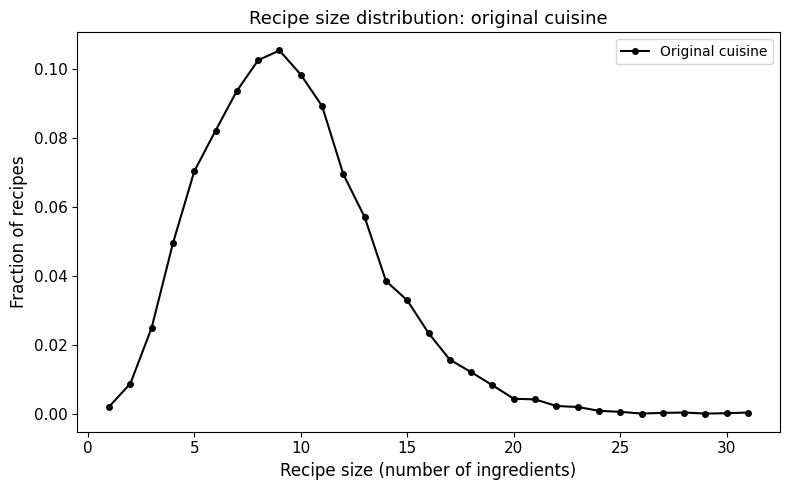

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sizes_axis, size_dist(orig_sizes), 'ko-', ms=4, lw=1.5, label='Original cuisine')
style(ax, 'Recipe size distribution: original cuisine')
ax.legend(); plt.tight_layout()
plt.savefig('outputs/Q2a_original_size_distribution.png', dpi=150); plt.show()

### Recipe size distribution of the randomly created recipes (10 sets)

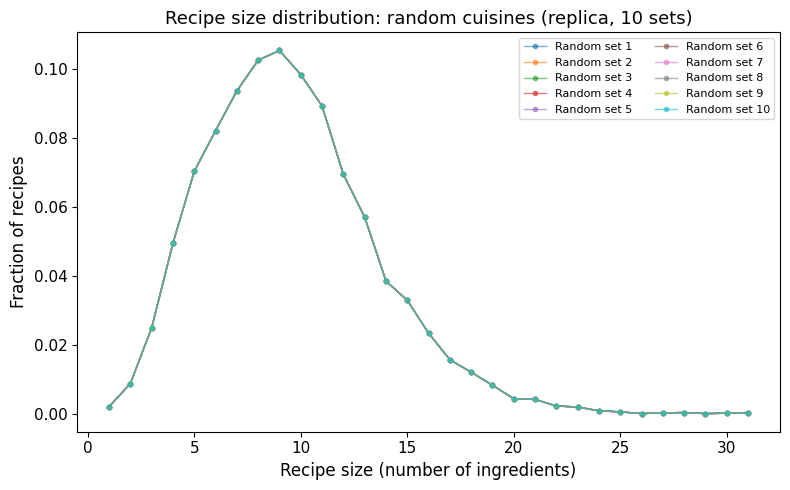

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
for i, cuisine in enumerate(random_a):
    d = size_dist(np.array([len(r) for r in cuisine]))
    ax.plot(sizes_axis, d, '-o', ms=3, lw=1, alpha=0.6, label=f'Random set {i+1}')
style(ax, 'Recipe size distribution: random cuisines (replica, 10 sets)')
ax.legend(fontsize=8, ncol=2); plt.tight_layout()
plt.savefig('outputs/Q2a_random_size_distribution.png', dpi=150); plt.show()

## 2(b) Size-controlled cuisine using inverse transformation (10 × original)
**Strategy (inverse transform sampling):**
1. Compute the probability mass function of recipe sizes in the original cuisine and its cumulative distribution function CDF(s).
2. Draw u ~ Uniform(0, 1).
3. The recipe size is the smallest s with CDF(s) ≥ u, i.e. s = CDF⁻¹(u). Sizes drawn this way follow the original size distribution.
4. Generate 10 × N sizes and fill each recipe with that many distinct ingredients chosen uniformly at random.

In [5]:
pmf = np.bincount(orig_sizes, minlength=max_size + 1) / N
cdf = np.cumsum(pmf)

n_random = 10 * N
u = rng.random(n_random)
new_sizes = np.searchsorted(cdf, u, side='left')
new_sizes = np.clip(new_sizes, 1, max_size)

random_b = [rng.choice(M, size=k, replace=False) for k in new_sizes]
print('random recipes created:', len(random_b), '(10 x original =', n_random, ')')
print('max |difference| between size distributions:', np.abs(size_dist(new_sizes) - size_dist(orig_sizes)).max())

random recipes created: 99990 (10 x original = 99990 )
max |difference| between size distributions: 0.0013101310131013108


### Recipe size distribution of the randomly created recipes (10 × original)

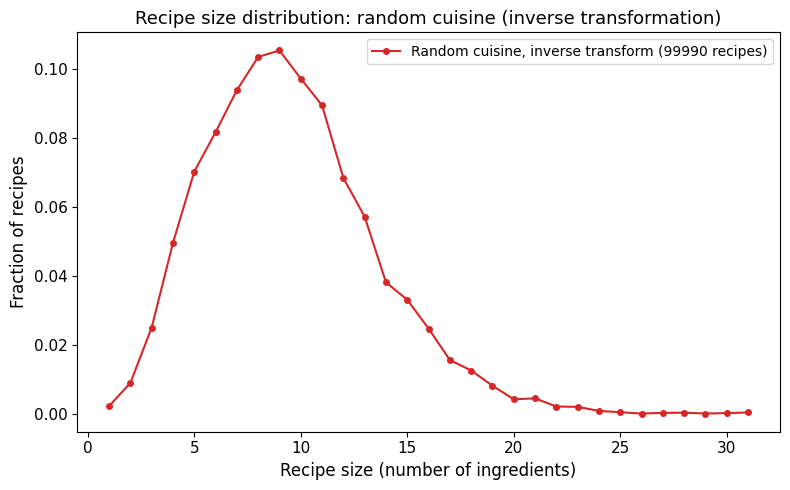

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sizes_axis, size_dist(new_sizes), 'o-', color='tab:red', ms=4, lw=1.5, label=f'Random cuisine, inverse transform ({n_random} recipes)')
style(ax, 'Recipe size distribution: random cuisine (inverse transformation)')
ax.legend(); plt.tight_layout()
plt.savefig('outputs/Q2b_random_size_distribution.png', dpi=150); plt.show()